# Effect of the lake fix on the MEGAN attribution figures

**Bug (found 2026-11-02, `gamma_eff_vs_GAMMA_check.ipynb` §2, fixed 2026-11-03 with the user's OK):** `megan_maps.load_factors` counted lake in `f_valid`, the land fraction where CLM defines `EPS_*`/`GAMMA*`. CLM leaves EPS/GAMMA missing on lake patches, so the right fraction is

$$f_{new} = \text{natveg}\,(1-\text{bare share}) + \text{crop}, \qquad f_{old} = f_{new} + \text{lake}.$$

**What it changes.** Only `f_valid`, which is constant in time (surface data). With $E = k\,f\,\varepsilon\,\gamma_{eff}$:

- $\gamma_{eff,new} = \gamma_{eff,old}\cdot f_{old}/f_{new}$ in each run (a level change: γ_eff was too low).
- In the LCC vs CTRL attribution, define $\delta = \Delta\ln f_{new} - \Delta\ln f_{old}$. Then **composition gains +δ; activity, residual and weighting each lose δ**. Emission, the partial γ's, CLM's GAMMA and the co-variation term do not change.
- δ ≠ 0 only where the cell has lake **and** the valid vegetated area changes between CTRL and LCC. Landunits are the same in both runs, so this means where the bare-ground share changes (checked in §1).

**Old figures:** `results/figures/megan_factors/before_lake_fix/*_before_lake_fix.png`; new ones in `results/figures/megan_factors/` (rerun of `analysis/megan_factor_maps.ipynb`, 2026-11-03).

Runs: `forcing_maps.BVOC_PAIRS` PD (CTRL_PD / LCC_PD) and FUT (CTRL_FUT / LCC_FUT), new chain, 2001–2014. Outputs: `lake_fix_effect_outputs/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from IPython.display import Image, display

ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(ROOT / "src"))
from boreal_forest_expansion.plotting import megan_maps as mm
from boreal_forest_expansion.plotting import forcing_maps as fm
from boreal_forest_expansion.plotting.forcing_maps import BVOC_PAIRS, open_class
from boreal_forest_expansion.plotting.style import set_default_style

set_default_style()
OUT = Path("lake_fix_effect_outputs")
(OUT / "figures").mkdir(parents=True, exist_ok=True)
(OUT / "tables").mkdir(parents=True, exist_ok=True)

EXPERIMENTS, GROUPS, SEASONS = ["PD", "FUT"], ["isoprene", "MTERP"], ["ANN", "JJA"]
LAT_MIN, MIN_SHARE = 45.0, 0.01          # as make_attribution_maps
FIG_DIR = ROOT / "results/figures/megan_factors"
for e in EXPERIMENTS:
    print(e, BVOC_PAIRS[e]["ctrl"], BVOC_PAIRS[e]["lcc"])

PD CTRL_PD LCC_PD
FUT CTRL_FUT LCC_FUT


## 1. Load the factors (fixed version) and rebuild the old version

`load_factors(..., lake_in_f_valid=False)` is the fixed code. The old version is rebuilt from it: $f_{old} = f_{new} + \text{lake}$, $\gamma_{eff,old} = \gamma_{eff,new}\,f_{new}/f_{old}$. The rebuild is checked against `lake_in_f_valid=True` for FUT isoprene ANN (both runs).
Also checked: CTRL and LCC have the same landunit fractions, so f changes only through the bare share.

In [2]:
def lake_fraction(alias):
    et = open_class(alias, "ET", 2001, 2014, "lnd")
    return et["PCT_LANDUNIT"].isel(time=0, ltype=4) / 100.0, et["PCT_LANDUNIT"].isel(time=0) / 100.0

lake, landunits = {}, {}
for e in EXPERIMENTS:
    for veg in ("ctrl", "lcc"):
        al = BVOC_PAIRS[e][veg]
        lake[al], landunits[al] = lake_fraction(al)
    c, l = BVOC_PAIRS[e]["ctrl"], BVOC_PAIRS[e]["lcc"]
    print(f"{e}: max |PCT_LANDUNIT LCC - CTRL| = {float(abs(landunits[l] - landunits[c]).max()):.2e}")

def old_version(x, alias):
    y = x.copy()
    y["f_valid"] = x["f_valid"] + lake[alias]
    y["gamma_eff"] = x["gamma_eff"] * x["f_valid"] / y["f_valid"]
    return y

data = {}   # (experiment, group, season) -> {"new": (ctrl, lcc), "old": (ctrl, lcc)}
for e in EXPERIMENTS:
    c, l = BVOC_PAIRS[e]["ctrl"], BVOC_PAIRS[e]["lcc"]
    for g in GROUPS:
        for s in SEASONS:
            a, b = mm.load_factors(c, g, s), mm.load_factors(l, g, s)
            data[e, g, s] = {"new": (a, b), "old": (old_version(a, c), old_version(b, l))}

# check the rebuild against the old code path
for veg, i in (("ctrl", 0), ("lcc", 1)):
    ref = mm.load_factors(BVOC_PAIRS["FUT"][veg], "isoprene", "ANN", lake_in_f_valid=True)
    reb = data["FUT", "isoprene", "ANN"]["old"][i]
    rel = abs(reb["gamma_eff"] / ref["gamma_eff"] - 1)
    print(f"FUT {veg}: rebuild vs lake_in_f_valid=True, max rel. diff gamma_eff = {float(rel.max()):.1e}, "
          f"f_valid = {float(abs(reb['f_valid'] - ref['f_valid']).max()):.1e}")

PD: max |PCT_LANDUNIT LCC - CTRL| = 0.00e+00
FUT: max |PCT_LANDUNIT LCC - CTRL| = 0.00e+00
FUT ctrl: rebuild vs lake_in_f_valid=True, max rel. diff gamma_eff = 4.4e-16, f_valid = 0.0e+00
FUT lcc: rebuild vs lake_in_f_valid=True, max rel. diff gamma_eff = 4.4e-16, f_valid = 0.0e+00


## 2. Where the fix matters: lake, the f ratio and the shift δ

Left: lake share of the land cell. Middle: $f_{old}/f_{new}$ (CTRL; the factor by which γ_eff was too low). Right: $100\,\delta$ = the amount moved from activity (and residual, weighting) to composition, in the same units as the attribution maps (100·Δln). Dashed line: modified cells.

findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


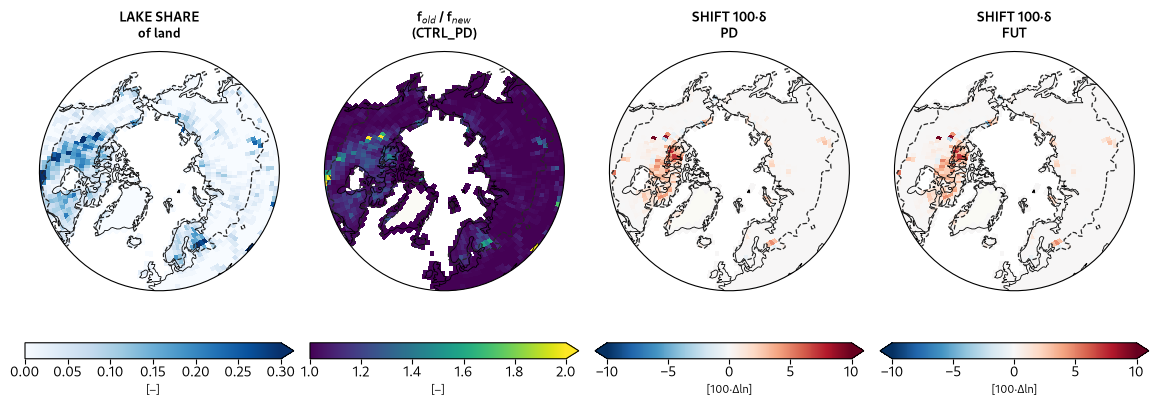

PD: cells >=45N with |100·δ| > 1: 129, > 5: 12 (of 1737); max |100·δ| = 9.7
FUT: cells >=45N with |100·δ| > 1: 129, > 5: 12 (of 1737); max |100·δ| = 9.7


In [3]:
def dln(x, y):
    return np.log(y / x).where((x > 0) & (y > 0))

delta = {}
for e in EXPERIMENTS:
    (an, bn), (ao, bo) = data[e, "isoprene", "ANN"]["new"], data[e, "isoprene", "ANN"]["old"]
    delta[e] = 100 * (dln(an["f_valid"], bn["f_valid"]) - dln(ao["f_valid"], bo["f_valid"]))

a0 = data["PD", "isoprene", "ANN"]["new"][0]
modified = mm._modified_mask(a0["MEG"].isel(year=0))
ratio = data["PD", "isoprene", "ANN"]["old"][0]["f_valid"] / a0["f_valid"]

fig, axes = fm.map_grid(1, 4)
panels = [
    (lake[BVOC_PAIRS["PD"]["ctrl"]], mcolors.Normalize(0, 0.3), "Blues", "LAKE SHARE\nof land", "[–]", "max"),
    (ratio, mcolors.Normalize(1, 2), "viridis", "f$_{old}$ / f$_{new}$\n(CTRL_PD)", "[–]", "max"),
    (delta["PD"], mcolors.TwoSlopeNorm(vmin=-10, vcenter=0, vmax=10), "RdBu_r", "SHIFT 100·δ\nPD", "[100·Δln]", "both"),
    (delta["FUT"], mcolors.TwoSlopeNorm(vmin=-10, vcenter=0, vmax=10), "RdBu_r", "SHIFT 100·δ\nFUT", "[100·Δln]", "both"),
]
for ax, (da, norm, cmap, title, units, ext) in zip(axes.ravel(), panels):
    p = mm._panel(ax, da, norm, cmap, title, LAT_MIN, modified=modified)
    fm._cbar_below(fig, ax, p, units, fm.CBAR_LABELSIZE, shrink=fm.CBAR_SHRINK, height=fm.CBAR_HEIGHT, extend=ext)
fig.savefig(OUT / "figures/lake_ratio_and_shift.png", dpi=200, bbox_inches="tight")
plt.show()

n = int(((a0["lat"] >= LAT_MIN) & np.isfinite(delta["FUT"])).sum())
for e in EXPERIMENTS:
    d = delta[e].where(delta[e]["lat"] >= LAT_MIN)
    print(f"{e}: cells >=45N with |100·δ| > 1: {int((abs(d) > 1).sum())}, > 5: {int((abs(d) > 5).sum())} (of {n}); "
          f"max |100·δ| = {float(abs(d).max()):.1f}")

## 3. Regional means before and after

Same numbers as under the attribution maps: 100·Δln, CTRL-emission-weighted mean ≥ 45°N (CTRL emission × cos lat, cells below 1 % of the 98th percentile blanked) ± 95 % CI of the yearly means. Terms not listed (emission, partial γ's, co-variation) are identical before and after (checked below).

In [4]:
PARTIAL = ["GAMMAL", "GAMMAT", "GAMMAP", "GAMMAA", "GAMMAC"]

def terms(a, b):
    """Same formulas as mm.make_attribution_maps."""
    part = [f for f in PARTIAL if f in a]
    d = {"emission": dln(a["MEG"], b["MEG"]),
         "composition": dln(a["EPS"] * a["f_valid"], b["EPS"] * b["f_valid"]),
         "activity": dln(a["gamma_eff"], b["gamma_eff"])}
    d.update({f: dln(a[f], b[f]) for f in part})
    d["residual"] = d["activity"] - sum(d[f] for f in part)
    d["weighting"] = d["activity"] - dln(a["GAMMA"], b["GAMMA"])
    d["co-variation"] = dln(a["GAMMA"], b["GAMMA"]) - sum(d[f] for f in part)
    return d

def weights(a):
    e = a["MEG"].mean("year")
    thr = MIN_SHARE * float(np.nanquantile(e.where(e["lat"] >= LAT_MIN).values, 0.98))
    return e > thr, (e * np.cos(np.deg2rad(e["lat"]))).where(e > thr, 0)

CHANGED = ["composition", "activity", "residual", "weighting"]
rows, maps = [], {}
for (e, g, s), v in data.items():
    keep, w = weights(v["new"][0])         # weights use MEG only: same before and after
    dn, do = terms(*v["new"]), terms(*v["old"])
    maps[e, g, s] = (dn, do)
    for t in dn:
        mn, hn = mm._interval(100 * dn[t].where(keep), w, LAT_MIN)
        mo, ho = mm._interval(100 * do[t].where(keep), w, LAT_MIN)
        rows.append(dict(experiment=e, group=g, season=s, term=t, before=mo, before_ci=ho,
                         after=mn, after_ci=hn, change=mn - mo))
tab = pd.DataFrame(rows)
tab.to_csv(OUT / "tables/regional_means_before_after.csv", index=False, float_format="%.4f")

unchanged = tab[~tab.term.isin(CHANGED)]
print(f"max |change| of the unchanged terms: {unchanged.change.abs().max():.1e}")
show = tab[tab.term.isin(["emission"] + CHANGED)].copy()
show["before"] = show.apply(lambda r: f"{r.before:+.2f} ± {r.before_ci:.2f}", axis=1)
show["after"] = show.apply(lambda r: f"{r.after:+.2f} ± {r.after_ci:.2f}", axis=1)
show["change"] = show.change.map(lambda x: f"{x:+.2f}")
pd.set_option("display.max_rows", 200)
display(show.set_index(["experiment", "group", "season", "term"])[["before", "after", "change"]])

max |change| of the unchanged terms: 0.0e+00


before          after change
experiment group    season term                                            
PD         isoprene ANN    emission      +1.97 ± 0.38   +1.97 ± 0.38  +0.00
                           composition  +12.23 ± 0.00  +12.28 ± 0.00  +0.05
                           activity     -10.27 ± 0.38  -10.32 ± 0.38  -0.05
                           residual      -9.47 ± 0.19   -9.52 ± 0.19  -0.05
                           weighting     -8.32 ± 0.11   -8.37 ± 0.11  -0.05
                    JJA    emission      +2.45 ± 0.41   +2.45 ± 0.41  +0.00
                           composition  +12.19 ± 0.00  +12.25 ± 0.00  +0.05
                           activity      -9.75 ± 0.41   -9.80 ± 0.41  -0.05
                           residual      -9.42 ± 0.18   -9.47 ± 0.18  -0.05
                           weighting     -7.78 ± 0.12   -7.83 ± 0.12  -0.05
           MTERP    ANN    emission      -0.65 ± 0.29   -0.65 ± 0.29  +0.00
                           composition   +1.91 ± 0.00   +1.98 ± 0.00  +0.06
                           activity      -2.56 ± 0.29   -2.62 ± 0.29  -0.06
                           residual      -0.92 ± 0.06   -0.98 ± 0.06  -0.06
                           weighting     +0.11 ± 0.08   +0.05 ± 0.08  -0.06
                    JJA    emission      +0.08 ± 0.30   +0.08 ± 0.30  +0.00
                           composition   +2.46 ± 0.00   +2.53 ± 0.00  +0.07
                           activity      -2.36 ± 0.29   -2.43 ± 0.29  -0.07
                           residual      -1.28 ± 0.09   -1.35 ± 0.09  -0.07
                           weighting     +0.39 ± 0.09   +0.33 ± 0.09  -0.07
FUT        isoprene ANN    emission      +0.33 ± 0.42   +0.33 ± 0.42  +0.00
                           composition  +13.84 ± 0.00  +13.89 ± 0.00  +0.05
                           activity     -13.50 ± 0.42  -13.55 ± 0.42  -0.05
                           residual     -10.18 ± 0.15  -10.24 ± 0.15  -0.05
                           weighting     -8.48 ± 0.07   -8.53 ± 0.07  -0.05
                    JJA    emission      +0.58 ± 0.42   +0.58 ± 0.42  +0.00
                           composition  +13.79 ± 0.00  +13.84 ± 0.00  +0.05
                           activity     -13.20 ± 0.43  -13.25 ± 0.43  -0.05
                           residual      -9.79 ± 0.14   -9.85 ± 0.14  -0.05
                           weighting     -8.01 ± 0.08   -8.07 ± 0.08  -0.05
           MTERP    ANN    emission      -1.70 ± 0.32   -1.70 ± 0.32  +0.00
                           composition   +2.94 ± 0.00   +3.01 ± 0.00  +0.07
                           activity      -4.65 ± 0.32   -4.71 ± 0.32  -0.07
                           residual      -1.08 ± 0.09   -1.15 ± 0.09  -0.07
                           weighting     +0.25 ± 0.08   +0.19 ± 0.08  -0.07
                    JJA    emission      -1.23 ± 0.32   -1.23 ± 0.32  +0.00
                           composition   +3.50 ± 0.00   +3.57 ± 0.00  +0.07
                           activity      -4.73 ± 0.32   -4.80 ± 0.32  -0.07
                           residual      -1.31 ± 0.13   -1.38 ± 0.13  -0.07
                           weighting     +0.40 ± 0.09   +0.33 ± 0.09  -0.07

## 4. Maps of the change, per case

After − before of the composition term (= 100·δ masked as in the attribution maps; activity, residual and weighting change by −100·δ), for each experiment × group × season. A check that it equals δ is printed.

PD isoprene ANN: max |diff − 100·δ| = 4.1e-14
PD isoprene JJA: max |diff − 100·δ| = 4.1e-14
PD MTERP ANN: max |diff − 100·δ| = 4.5e-14
PD MTERP JJA: max |diff − 100·δ| = 4.5e-14
FUT isoprene ANN: max |diff − 100·δ| = 4.1e-14
FUT isoprene JJA: max |diff − 100·δ| = 4.1e-14
FUT MTERP ANN: max |diff − 100·δ| = 4.5e-14
FUT MTERP JJA: max |diff − 100·δ| = 4.5e-14


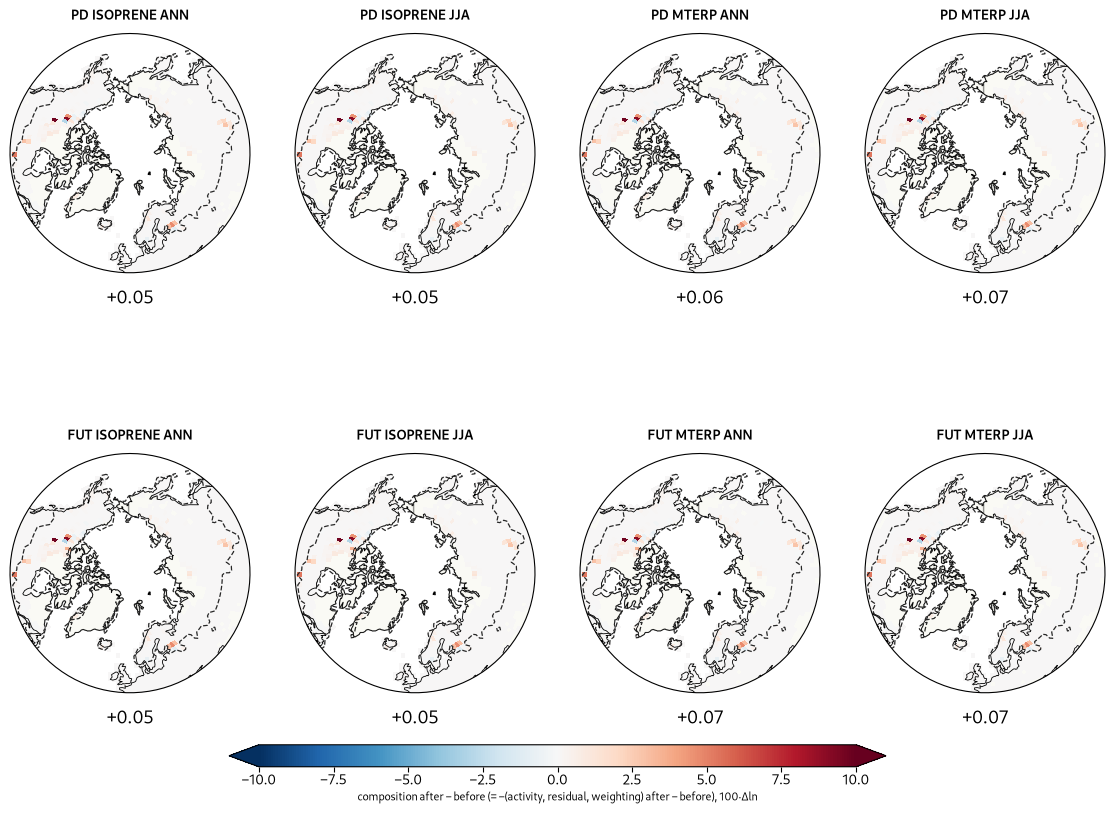

In [5]:
keys = list(maps)
fig, axes = fm.map_grid(2, 4, titles_every_row=True)
norm = mcolors.TwoSlopeNorm(vmin=-10, vcenter=0, vmax=10)
for ax, k in zip(axes.ravel(), keys):
    e, g, s = k
    dn, do = maps[k]
    keep, w = weights(data[k]["new"][0])
    diff = (100 * (dn["composition"] - do["composition"])).mean("year").where(keep)
    err = float(abs(diff - delta[e].where(keep)).max())
    md = tab.query("experiment == @e and group == @g and season == @s and term == 'composition'").change.item()
    p = mm._panel(ax, diff, norm, "RdBu_r", f"{e} {g.upper()} {s}", LAT_MIN, modified=modified,
                  text=f"{md:+.2f}")
    print(f"{e} {g} {s}: max |diff − 100·δ| = {err:.1e}")
fm._cbar_below(fig, axes[-1, :], p, "composition after − before (= −(activity, residual, weighting) after − before), 100·Δln",
               fm.CBAR_LABELSIZE_SHARED, shrink=0.6)
fig.savefig(OUT / "figures/composition_change_by_case.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Before / after figures (FUT and PD isoprene, ANN)

The figure files themselves, old above, new below. The FUT subtitle also lost the stale "different land spin-ups" note (both FUT runs are on the CO₂-fix chain).

BEFORE: results/figures/megan_factors/before_lake_fix/FUT_isoprene_attribution_ANN_2001_2014_before_lake_fix.png


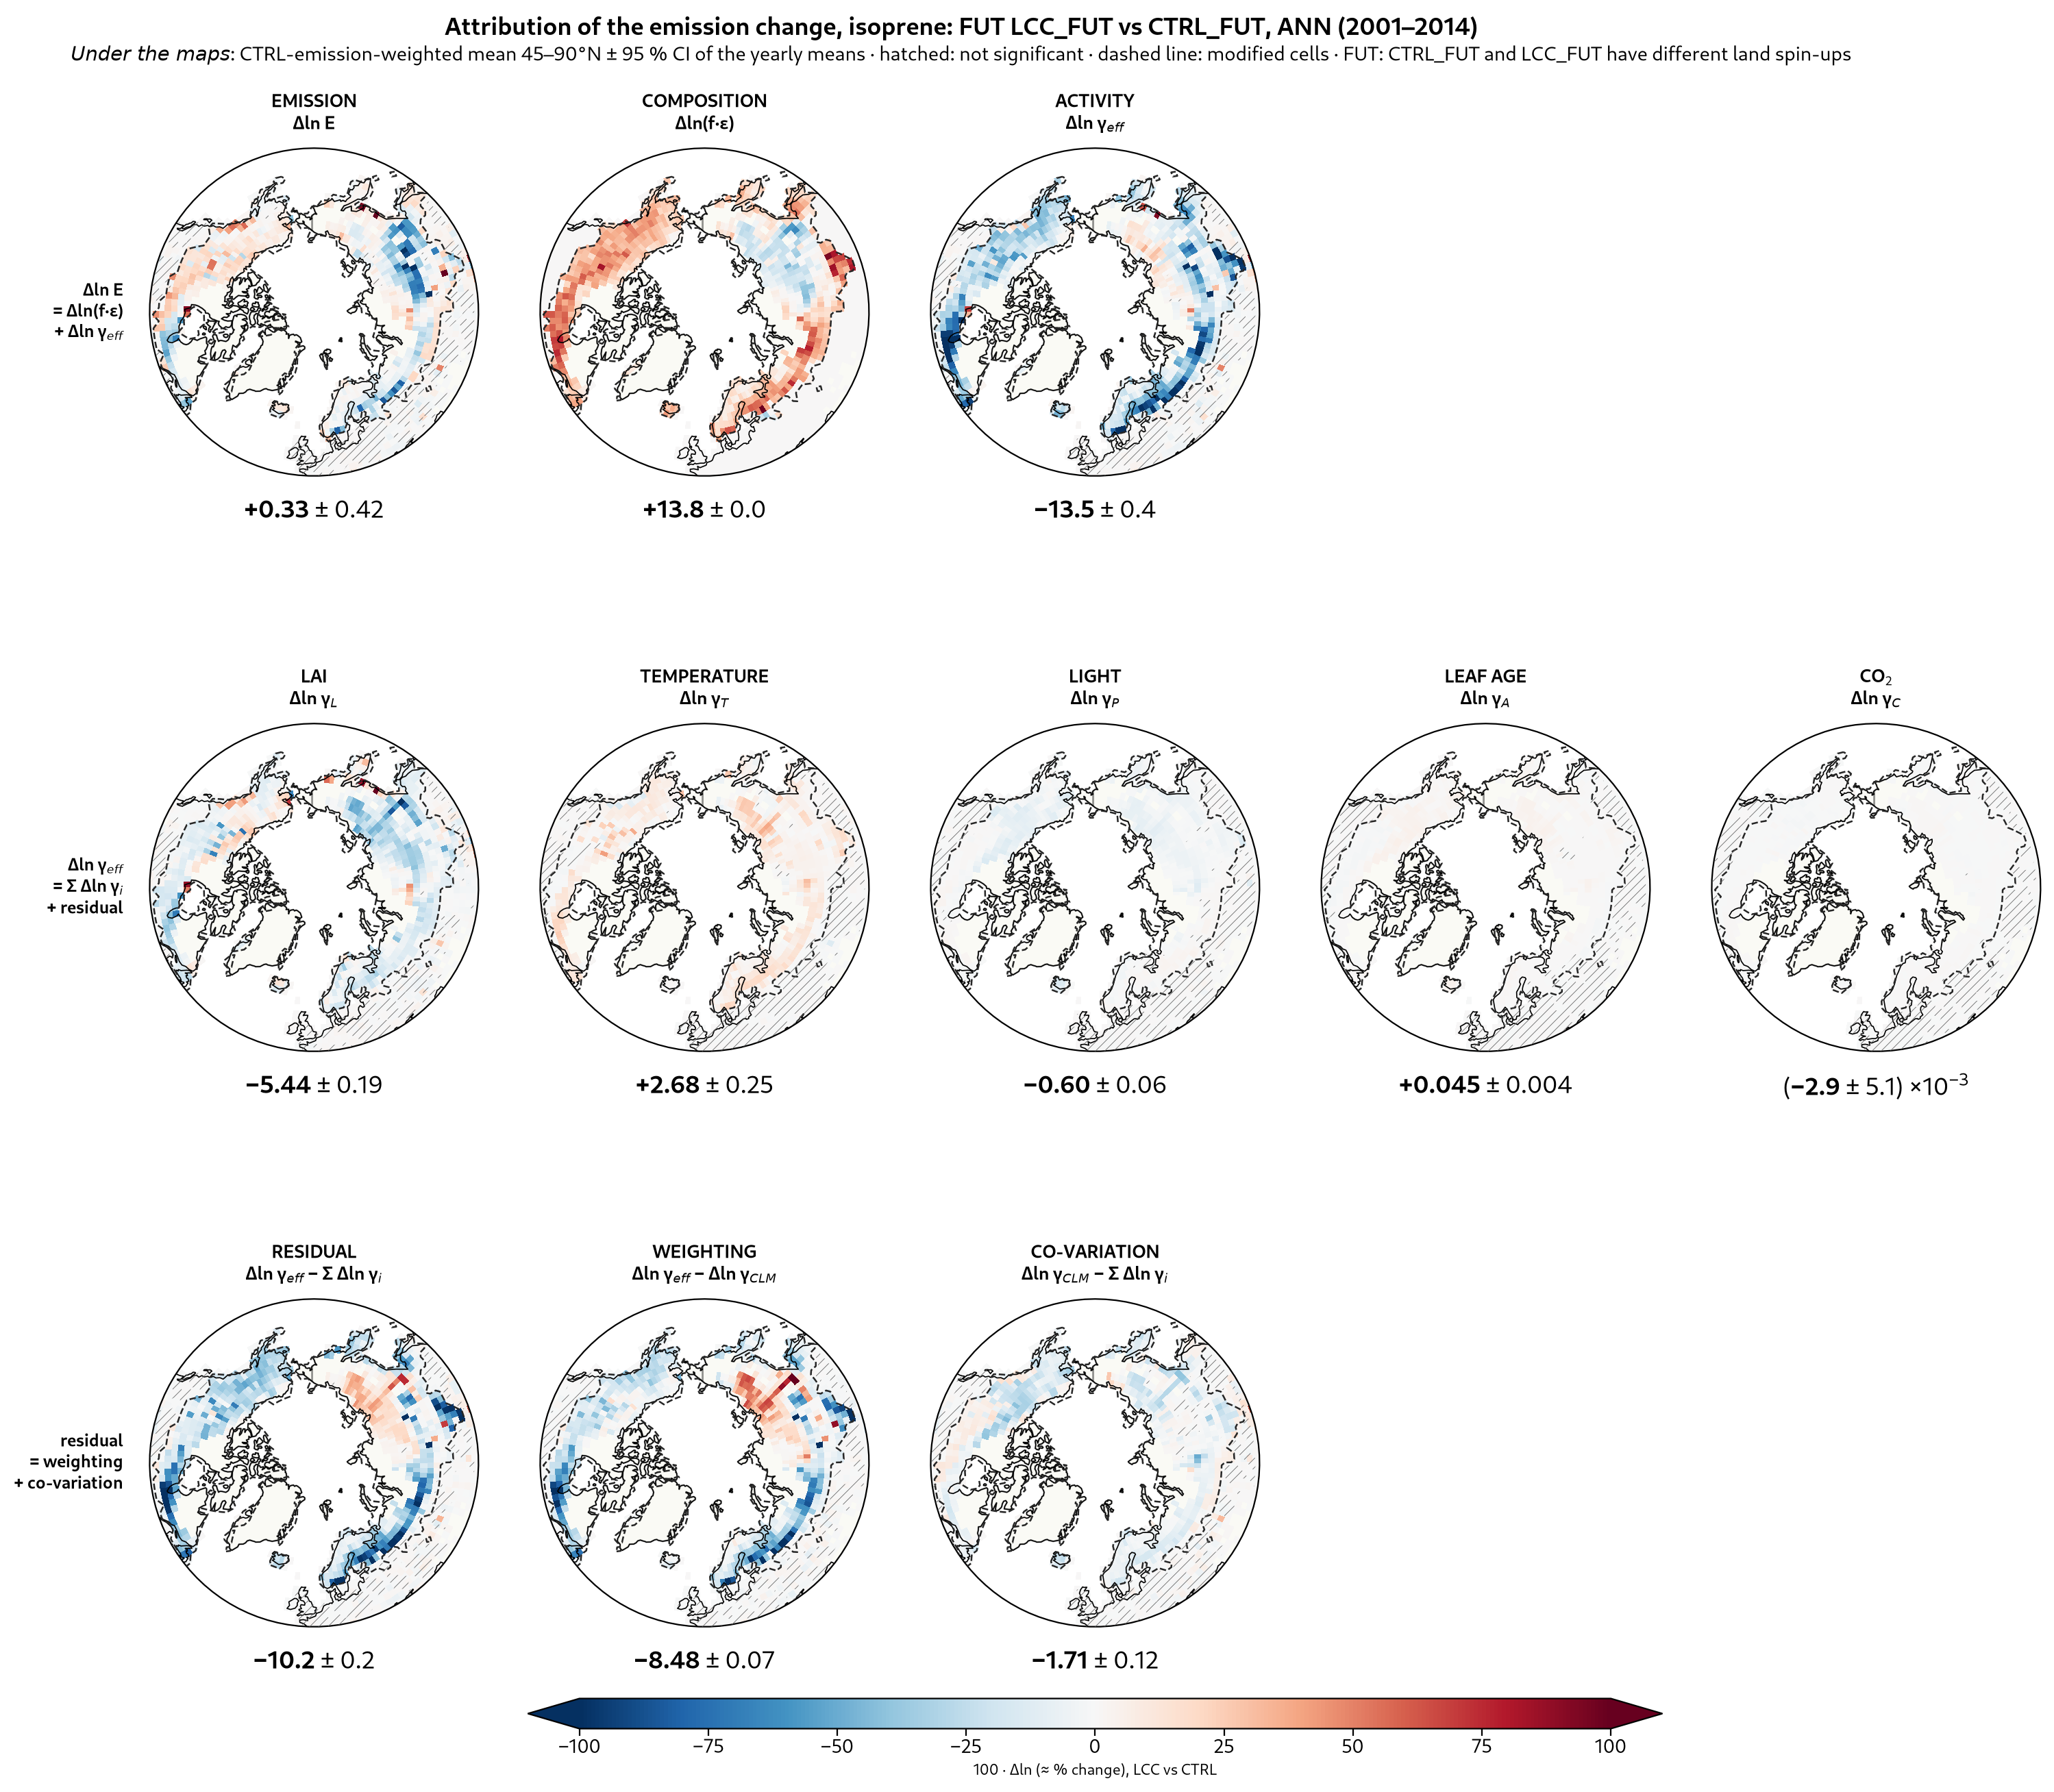

AFTER: results/figures/megan_factors/FUT_isoprene_attribution_ANN_2001_2014.png


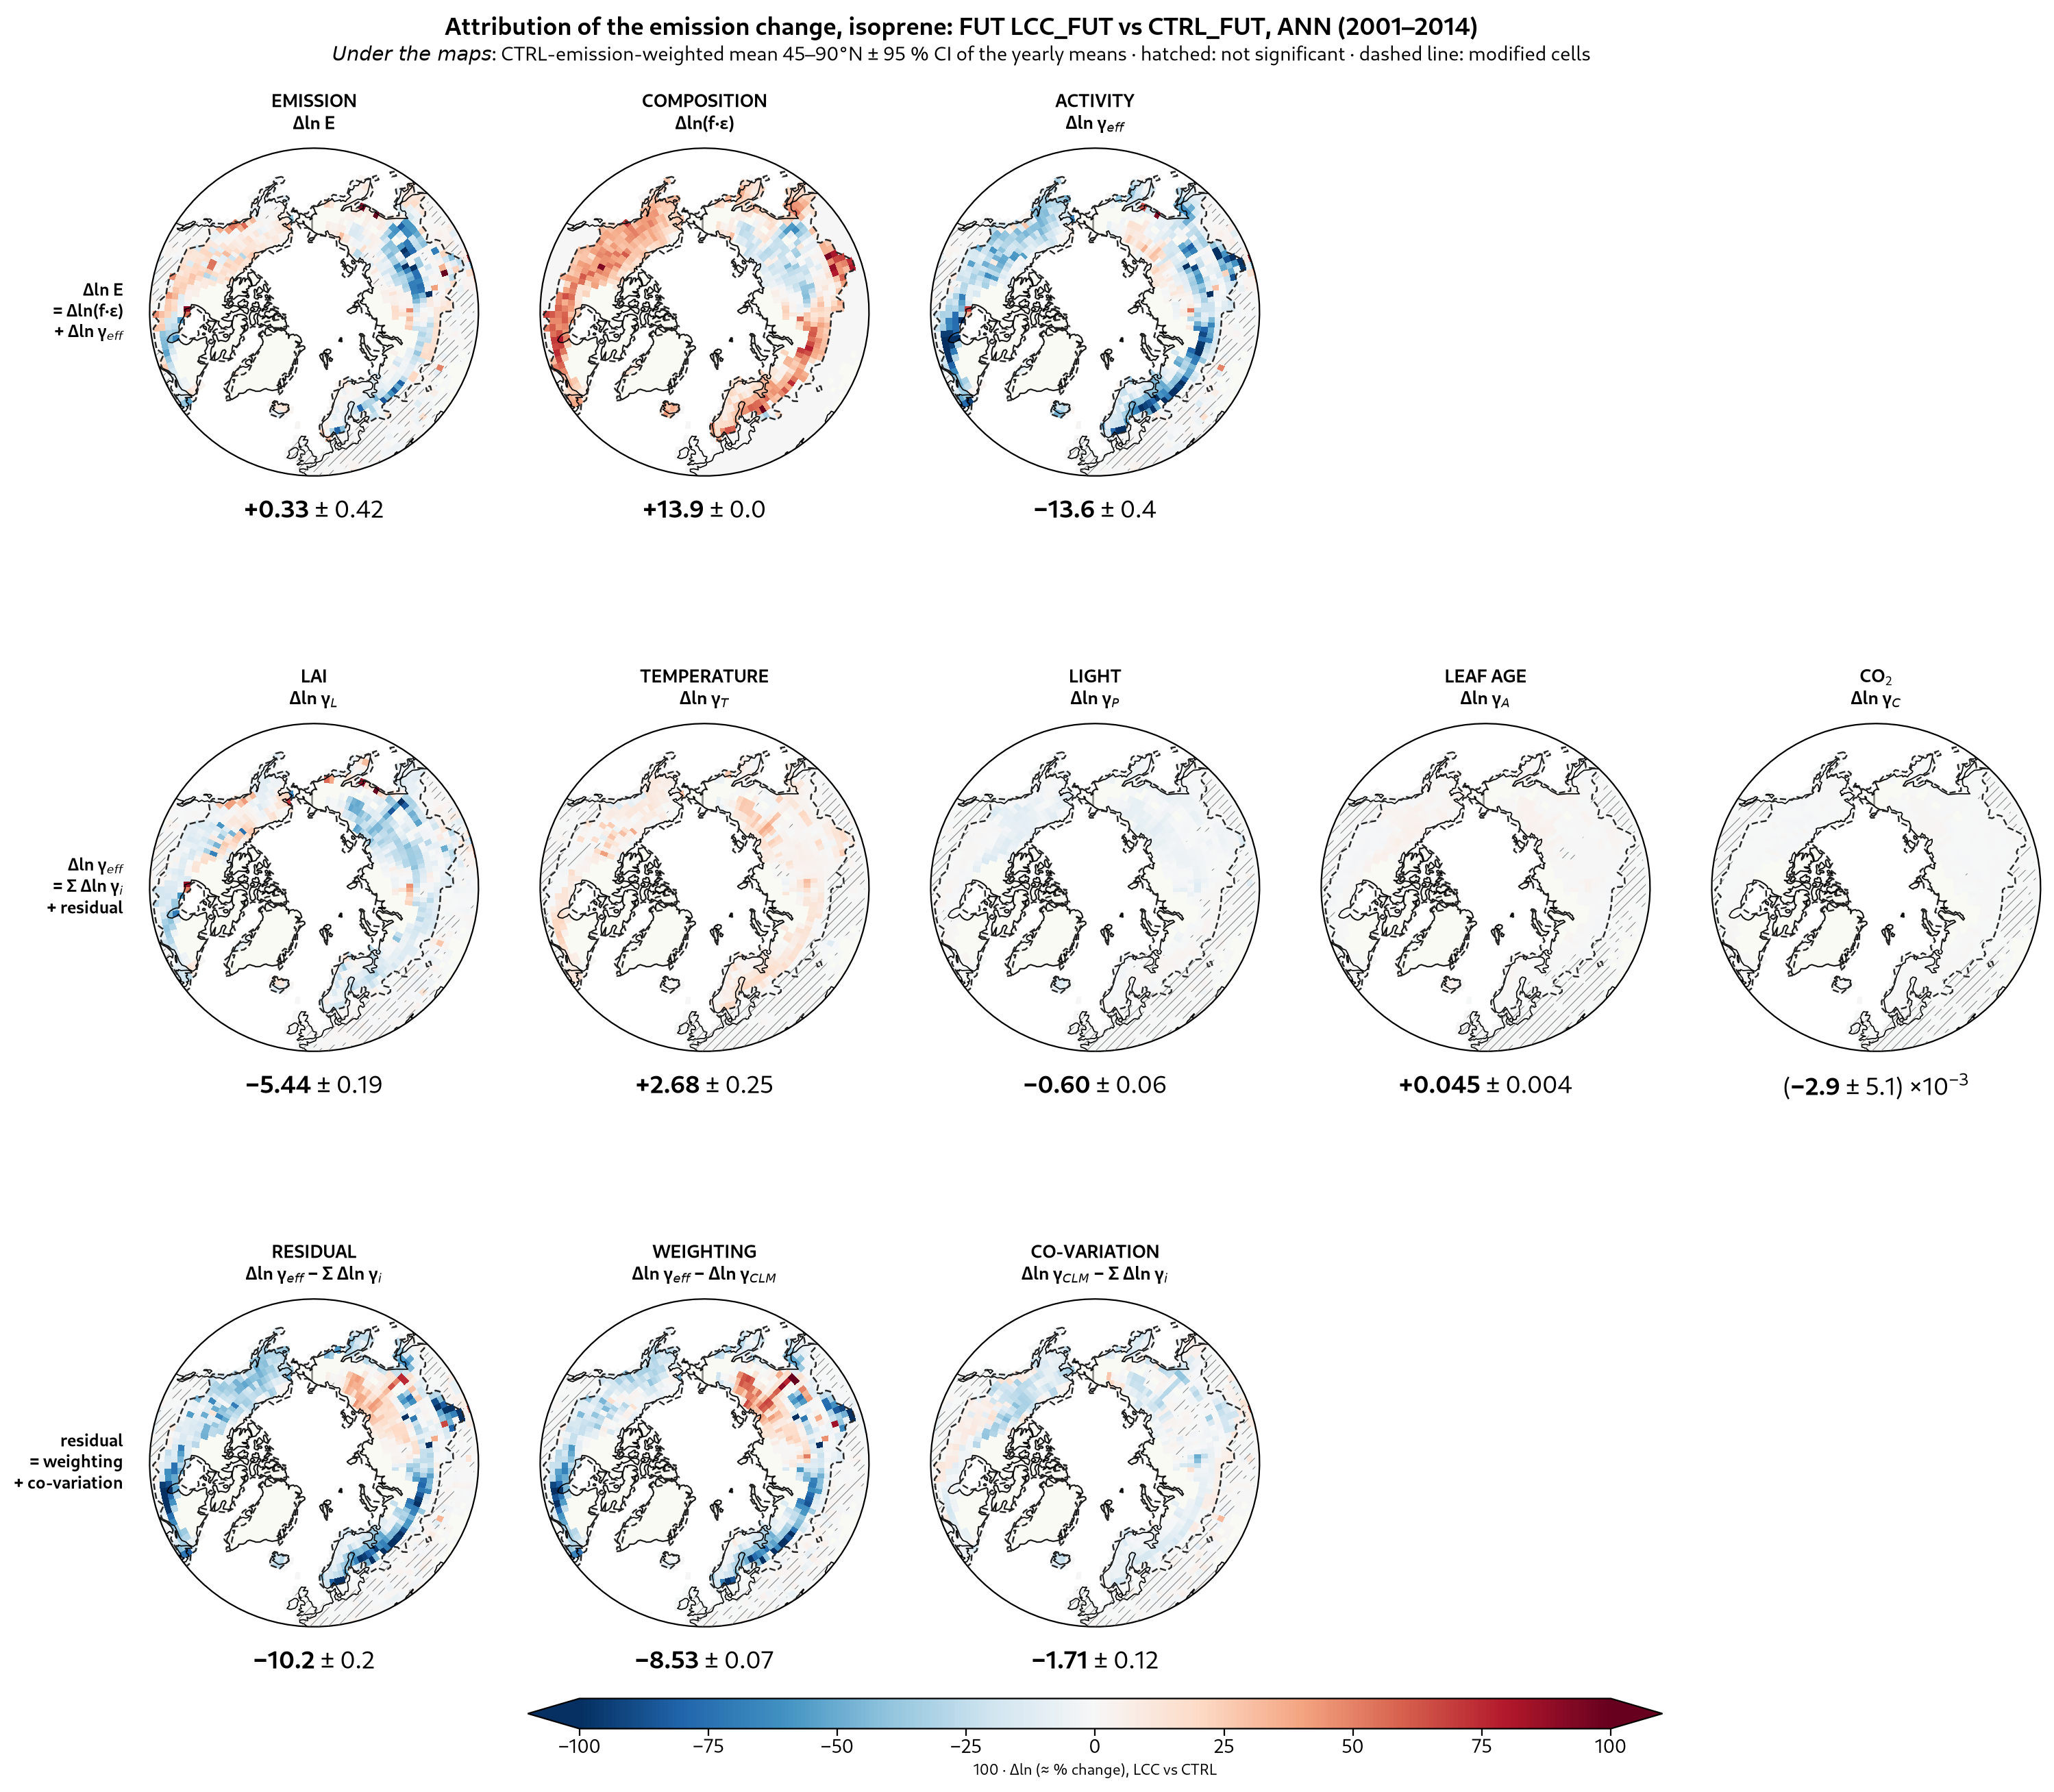

BEFORE: results/figures/megan_factors/before_lake_fix/PD_isoprene_attribution_ANN_2001_2014_before_lake_fix.png


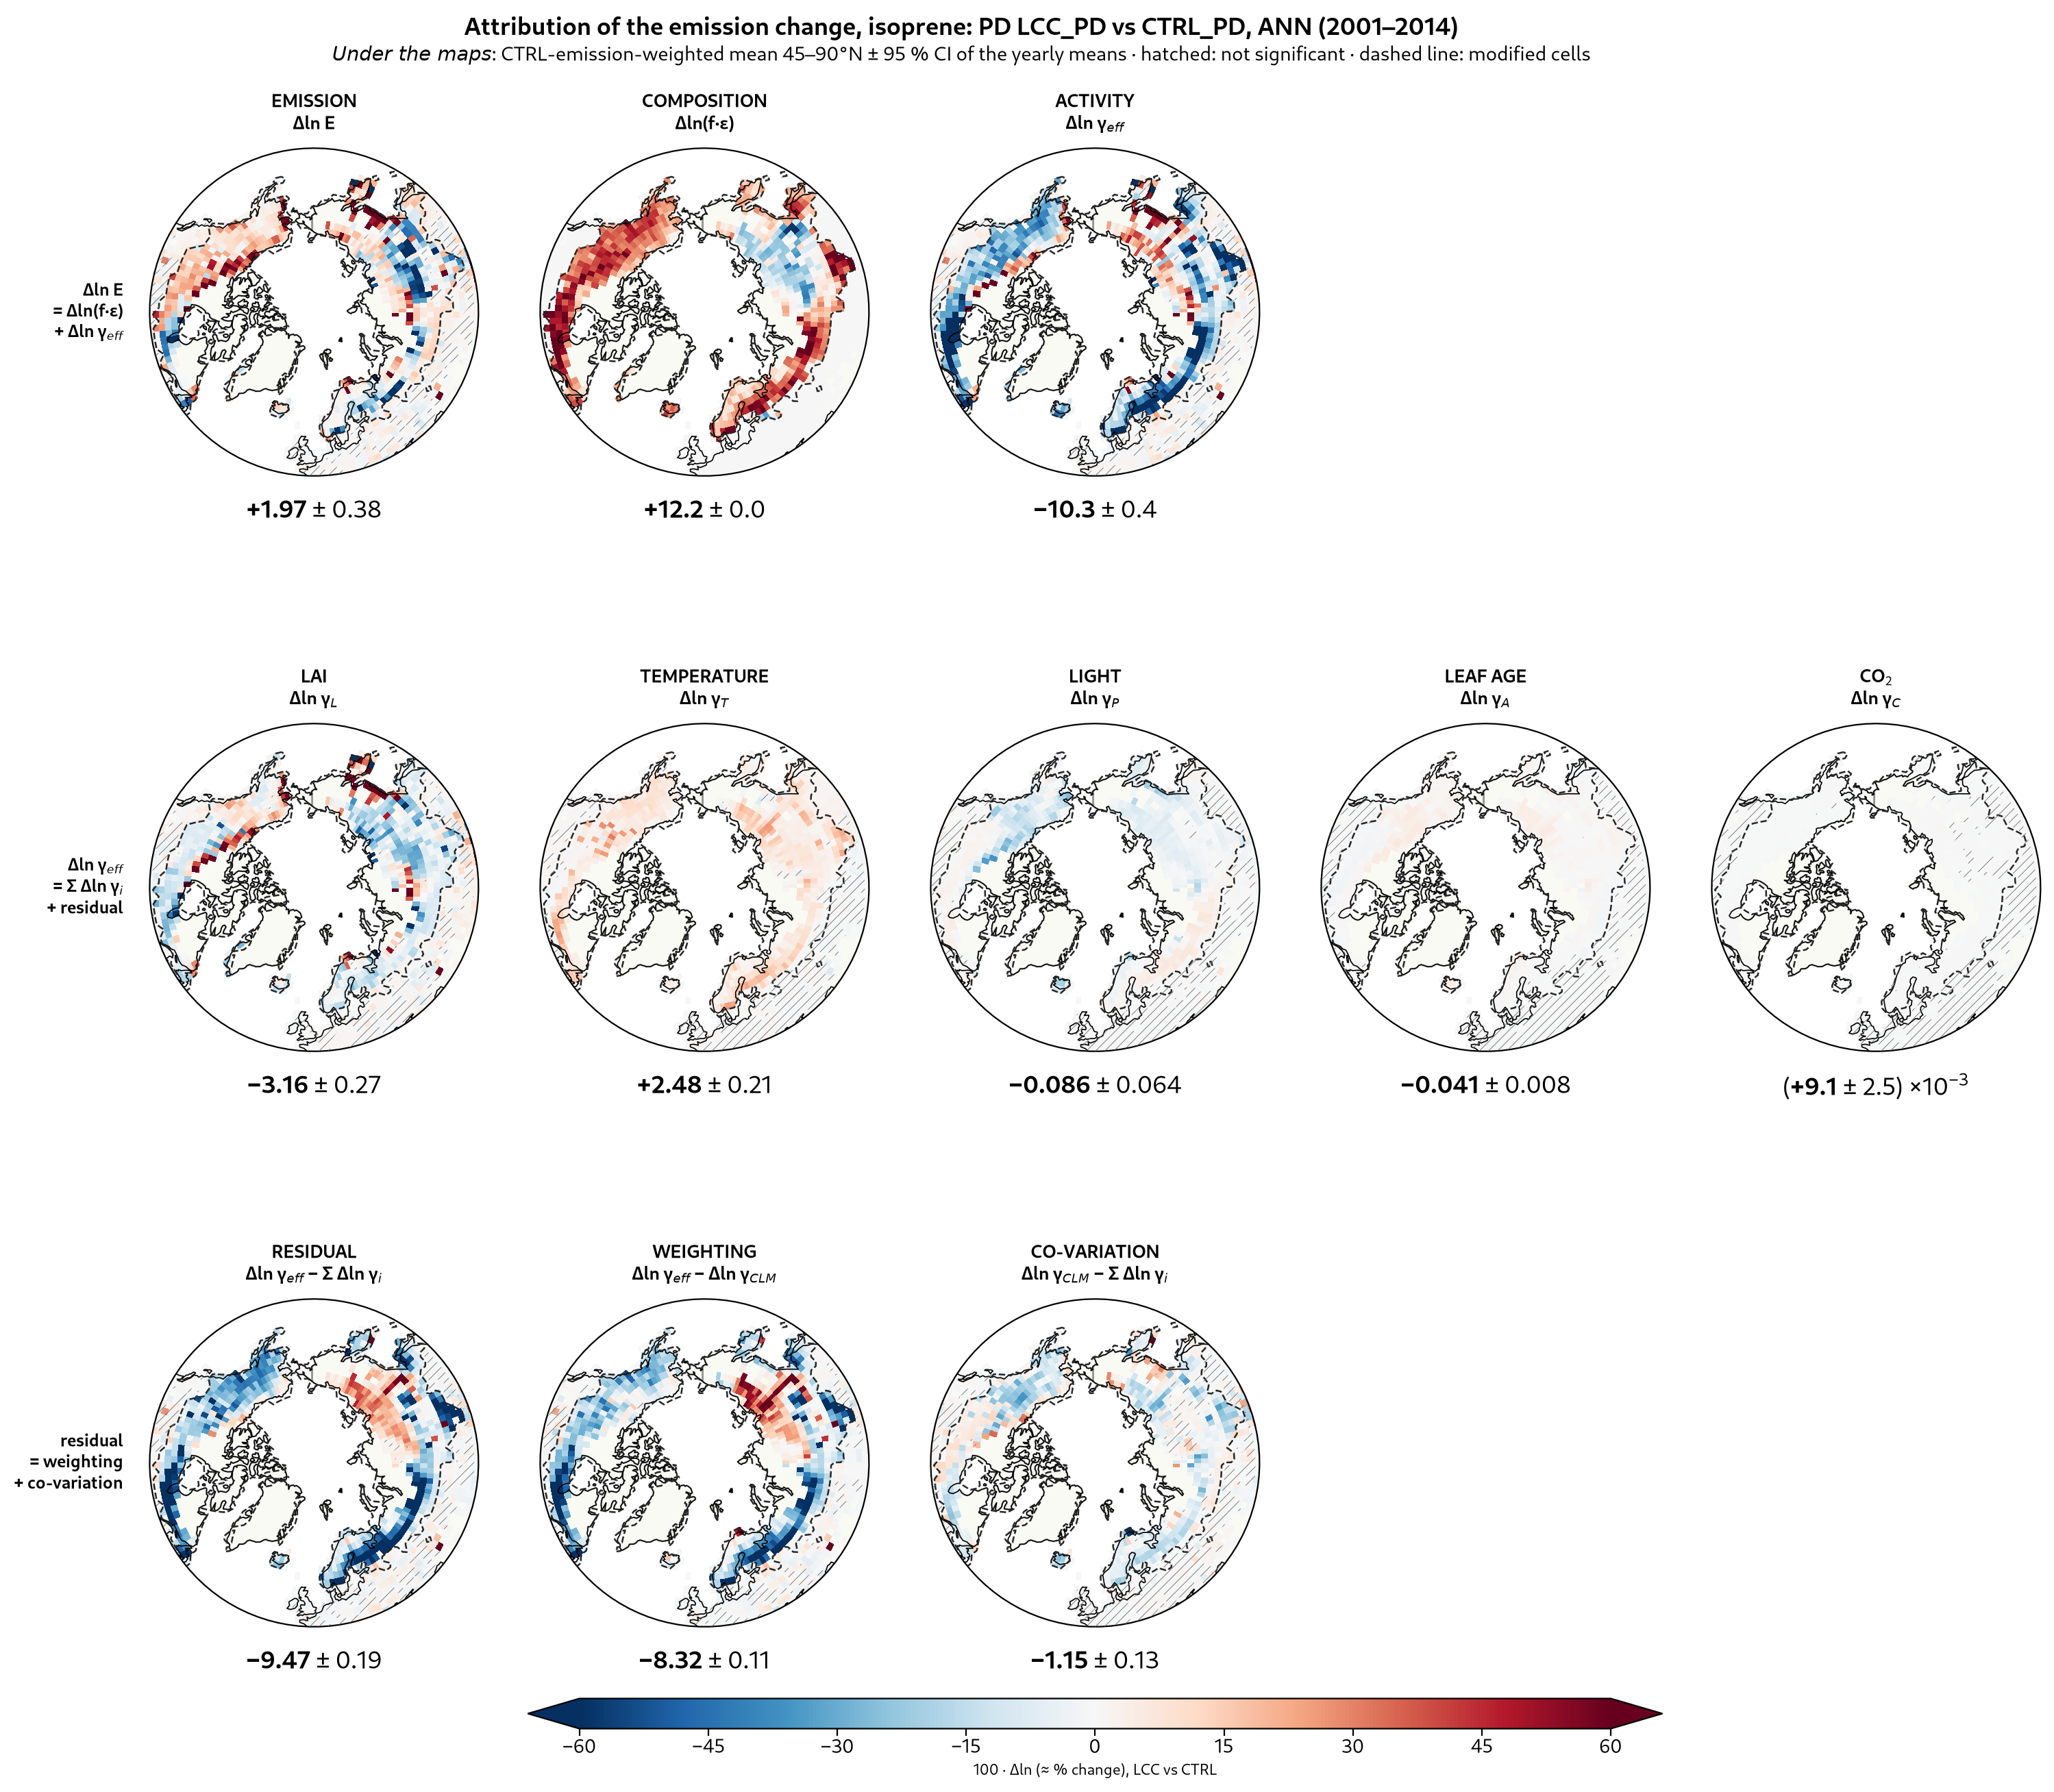

AFTER: results/figures/megan_factors/PD_isoprene_attribution_ANN_2001_2014.png


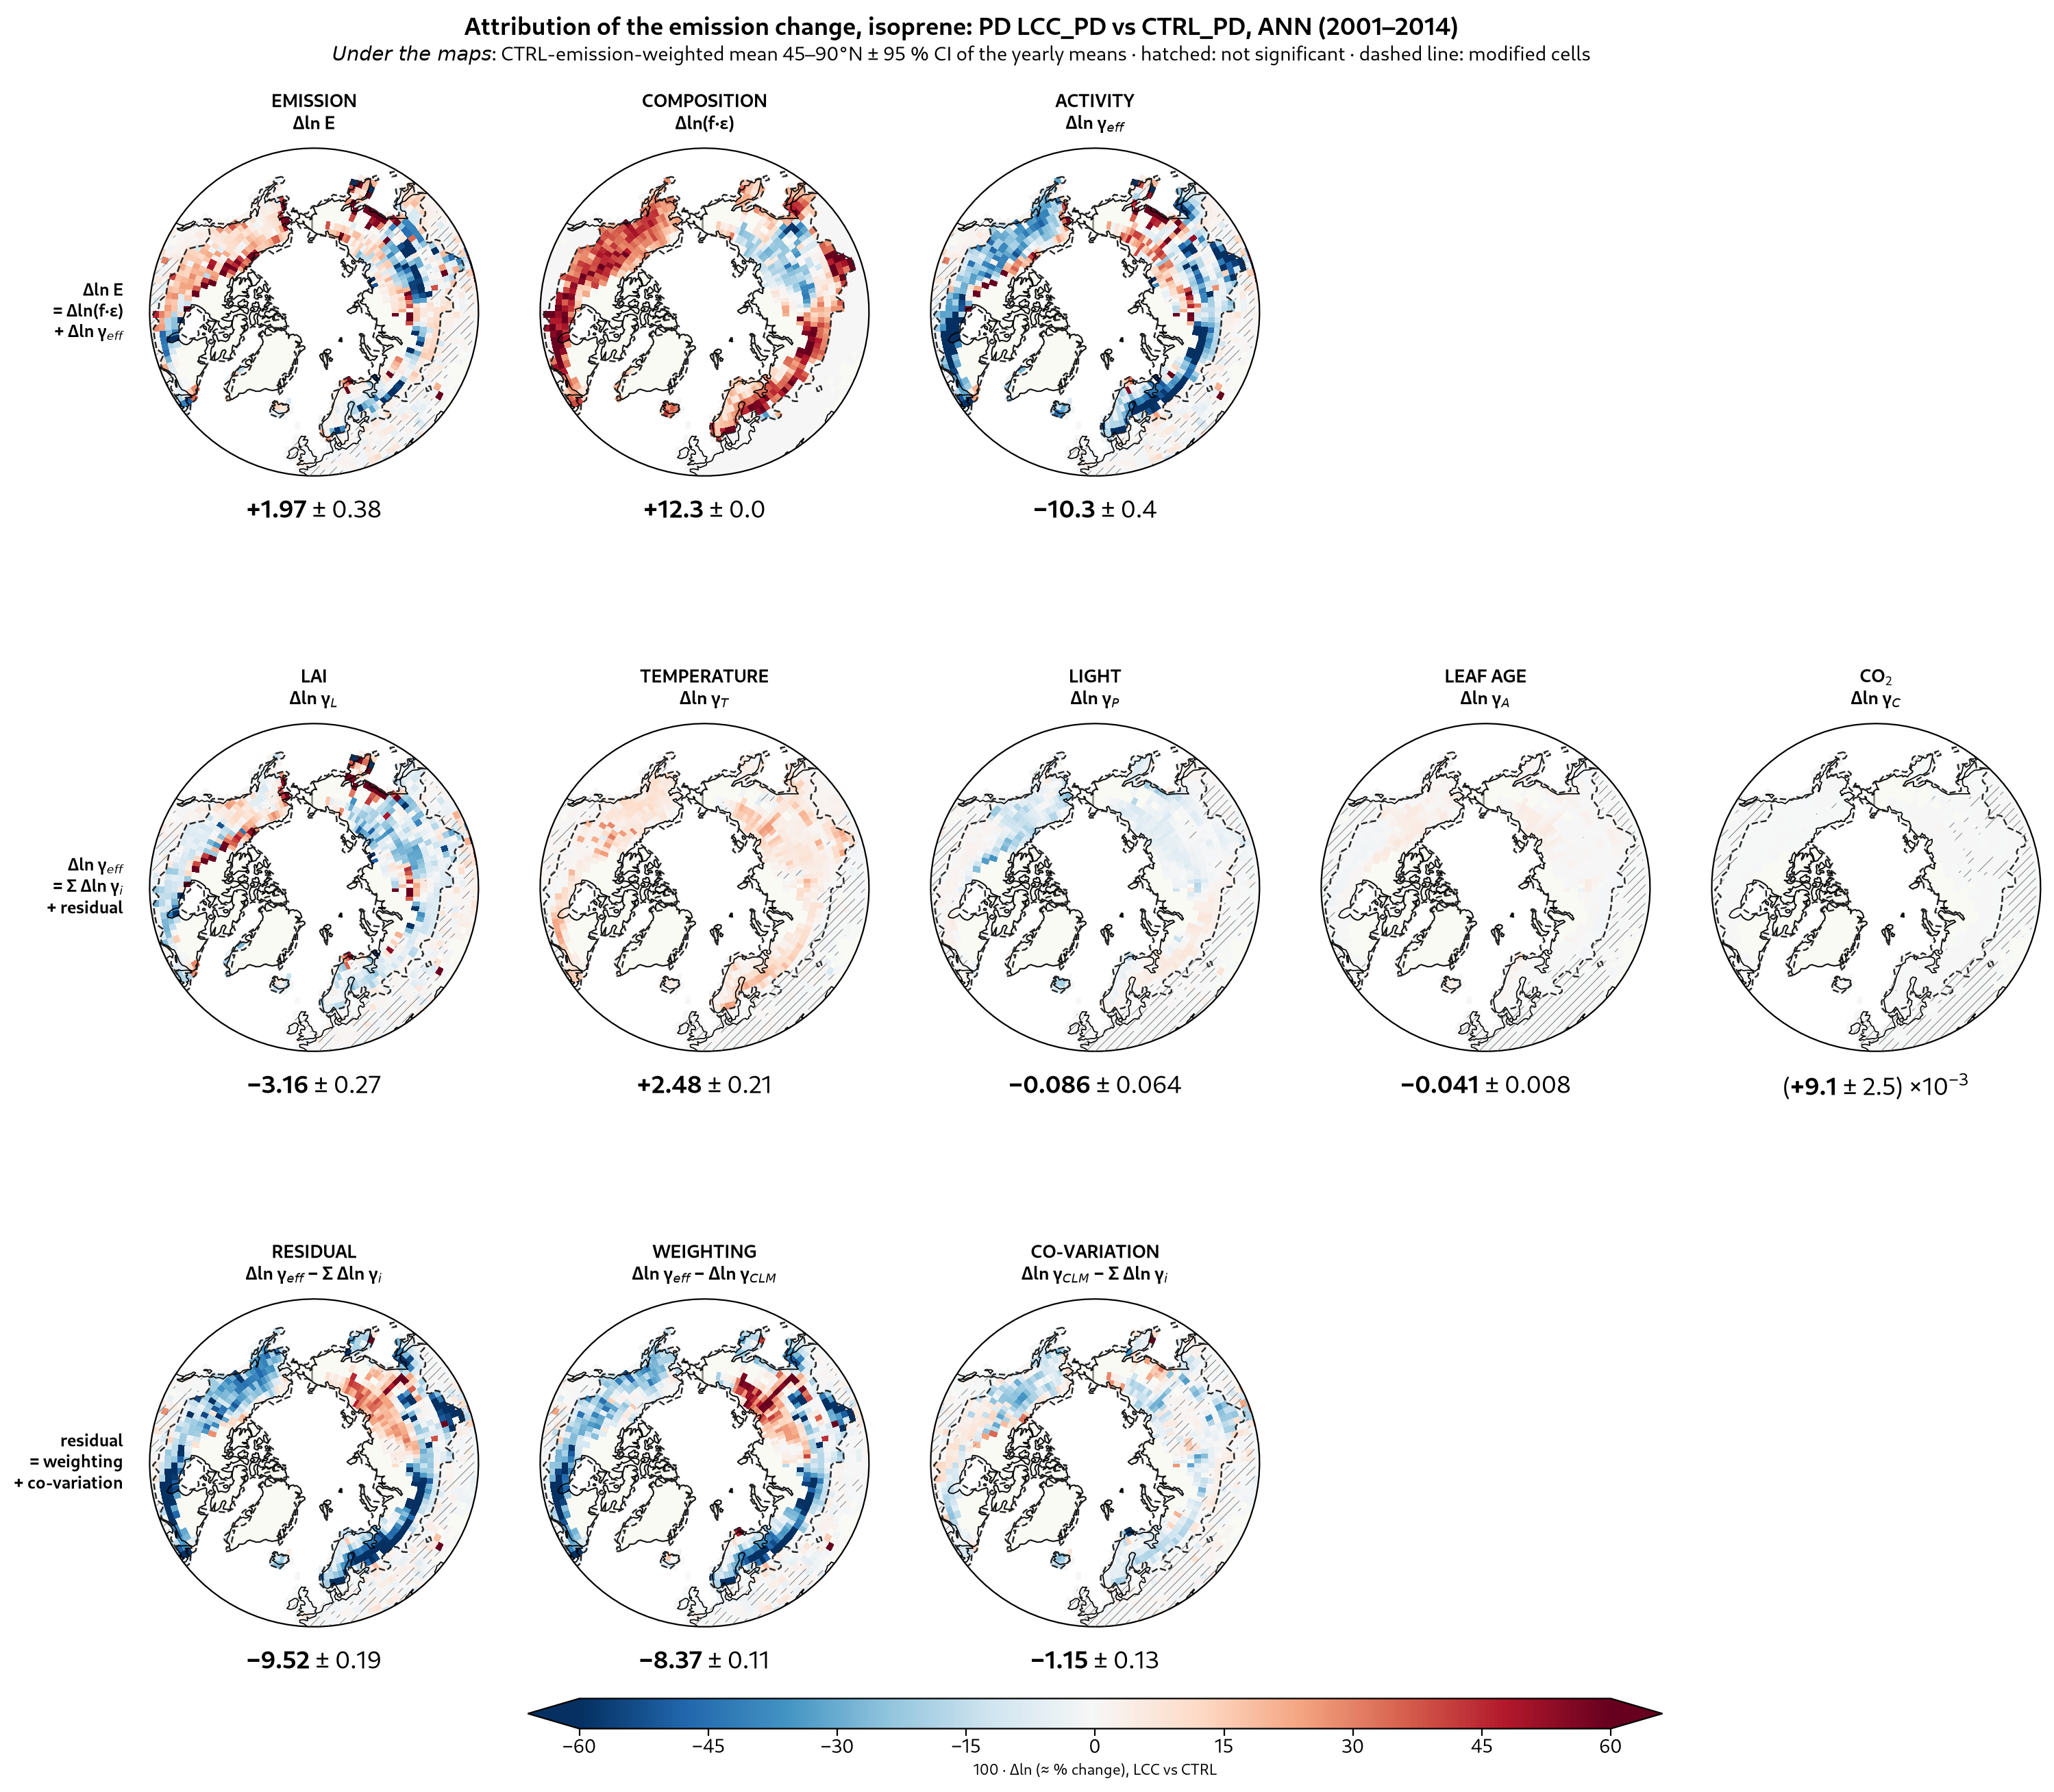

In [6]:
for name in ["FUT_isoprene_attribution_ANN_2001_2014", "PD_isoprene_attribution_ANN_2001_2014"]:
    for label, path in (("BEFORE", FIG_DIR / "before_lake_fix" / f"{name}_before_lake_fix.png"),
                        ("AFTER", FIG_DIR / f"{name}.png")):
        print(f"{label}: {path.relative_to(ROOT)}")
        display(Image(filename=str(path), width=900))

## 6. Verdict (2026-11-03)

**The lake fix changes the attribution figures very little (a).**

- **Checks:** CTRL and LCC have identical landunit fractions (max diff 0), so δ comes only from the bare-share change. The old version rebuilt from the new one matches `lake_in_f_valid=True` to 4e-16. Emission, partial γ's and co-variation are unchanged (max diff 0). Per cell, the composition change equals 100·δ to 4e-14.
- **Regional means (≥ 45°N, CTRL-emission-weighted, 100·Δln):** composition goes up by **+0.05 to +0.07** in all 8 cases; activity, residual and weighting go down by the same amount. That is smaller than the CIs of activity (±0.3–0.4) and well below the size of the terms. Example, FUT isoprene ANN: composition +13.84 → +13.89, activity −13.50 → −13.55, residual −10.18 → −10.24, weighting −8.48 → −8.53. The largest relative change is the small MTERP weighting term (PD ANN +0.11 → +0.05, FUT ANN +0.25 → +0.19).
- **Maps:** |100·δ| > 1 in 129 of 1737 cells ≥ 45°N and > 5 in 12 (max 9.7). They sit mostly in the Canadian Arctic Archipelago and northern Canada and Alaska (lake-rich tundra where the bare share changes), where emission is low. PD and FUT have the same δ because they use the same CTRL/LCC surface data.
- **Level of γ_eff in each run:** this changes more (f_old/f_new up to 6.3, mostly 1.0–1.3 in lake-rich Canada and Scandinavia) and shows in the factor figures (γ_eff column), not in the attribution.
- **Conclusion:** the readings of the attribution figures made before the fix still hold; use the new figures from now on.